# Topografía de las regiones candidatas (v0) · Tierra y Luna
**NASA Space Apps Challenge 2026** · El reto pide caracterizar los análogos por topografía, y usar datos de la Luna además de la Tierra.

**Qué mide**: la **pendiente** del terreno de cada región candidata (Luna y Marte) y la compara con la de los **lugares donde alunizaron
las misiones Apollo**, medida con el altímetro lunar LOLA a la misma escala.

| Datos | Uso | Resolución |
|---|---|---|
| NASA ASTER GDEM v3 (`ASTGTM` v003, LP DAAC) | elevación de la Tierra, teselas de 1° × 1° | 30 m (1″), 83° N – 83° S |
| NASA LRO LOLA, `LDEM_128` (PDS, LRO-L-LOLA-4-GDR-V1.0) | elevación de la Luna | 128 píxeles/grado (~237 m) |
| Coordenadas de los módulos lunares Apollo (LROC, 2016) | sitios de referencia | — |

**Escalas**: pendiente a **30 m** (detalle del terreno en la Tierra) y a **~240 m** (la Tierra promediada a la escala de LOLA, para comparar).

**Por tandas y sin llenar Drive**: cada tesela se descarga a la carpeta temporal de Colab, se procesa y se borra. En Drive solo queda un
resumen por tesela (unos KB) en `03_datos/cache_api/topografia/`. Cada ejecución procesa como mucho `MAX_TESELAS_POR_EJECUCION`
teselas nuevas: si quedan pendientes, vuelve a ejecutar el notebook y sigue donde lo dejó.

## 0. Instalación

In [1]:
!pip install -q earthaccess rasterio

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.


## 1. Configuración

In [2]:
import os, re, json, time, glob, datetime, unicodedata
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt
import earthaccess, rasterio
from rasterio import features
from shapely.geometry import shape, box
from IPython.display import display
from google.colab import drive, userdata

drive.mount("/content/drive")
for raiz in ["/content/drive/MyDrive", "/content/drive/My Drive"]:
    if os.path.isdir(raiz):
        break
BASE = f"{raiz}/Hackathon Nasa"
VERSION = "topografia_v0"
RES, WEB = f"{BASE}/04_resultados/{VERSION}", f"{BASE}/06_web/{VERSION}"
CACHE = f"{BASE}/03_datos/cache_api/topografia"
TMP = "/content/tmp/topografia"
for d in (RES, WEB, CACHE, TMP):
    os.makedirs(d, exist_ok=True)

# --- Parámetros de las tandas ---
CUERPOS = ["luna", "marte"]          # regiones candidatas que se procesan (en este orden)
MAX_TESELAS_POR_REGION = 6           # teselas de 1° por región (las de mayor solape); limita el tiempo en regiones enormes
MAX_TESELAS_POR_EJECUCION = 150      # teselas nuevas por ejecución (~4 min por cada 60); vuelve a ejecutar para continuar
PASO_BIN = 0.25; BINS = np.arange(0, 90 + PASO_BIN, PASO_BIN)   # histogramas de pendiente (grados)

FIGURAS = f"{RES}/figuras"; os.makedirs(FIGURAS, exist_ok=True)
_mostrar = getattr(plt, "_show_original", plt.show); plt._show_original = _mostrar
_n_fig = [0]
def _mostrar_y_guardar(*a, **k):
    fig = plt.gcf()
    if fig.axes:
        _n_fig[0] += 1
        titulo = next((ax.get_title() for ax in fig.axes if ax.get_title()), "figura")
        slug = re.sub(r"[^a-zA-Z0-9]+", "_", unicodedata.normalize("NFKD", titulo).encode("ascii", "ignore").decode()).strip("_").lower()[:50]
        fig.savefig(f"{FIGURAS}/fig_{_n_fig[0]:02d}_{slug}.png", dpi=80, bbox_inches="tight")
    _mostrar(*a, **k)
plt.show = _mostrar_y_guardar

os.environ["EARTHDATA_USERNAME"] = userdata.get("EARTHDATA_USERNAME")
os.environ["EARTHDATA_PASSWORD"] = userdata.get("EARTHDATA_PASSWORD")
auth = earthaccess.login(strategy="environment")
SESION = earthaccess.get_requests_https_session()
entrada = json.load(open(f"{BASE}/06_web/manifest.json", encoding="utf-8"))
print("Earthdata:", auth.authenticated, "| cuerpos:", {k: v["carpeta"] for k, v in entrada["cuerpos"].items()})

Mounted at /content/drive
Earthdata: True | cuerpos: {'marte': 'v1.3', 'luna': 'luna_v0.3'}


## 2. Regiones y teselas
Se usan los polígonos exportados para la web. Para cada región se eligen las teselas de 1° × 1° que más se solapan con ella.

In [3]:
def nombre_tesela(lat0, lon0):
    return f"{'N' if lat0 >= 0 else 'S'}{abs(lat0):02d}{'E' if lon0 >= 0 else 'W'}{abs(lon0):03d}"

filas = []
for cuerpo in CUERPOS:
    info = entrada["cuerpos"][cuerpo]
    gj = json.load(open(f"{BASE}/06_web/{info['carpeta']}/regiones.geojson", encoding="utf-8"))
    for ft in gj["features"]:
        g = shape(ft["geometry"]); p = ft["properties"]
        oeste, sur, este, norte = g.bounds
        teselas = []
        for la in range(int(np.floor(sur)), int(np.ceil(norte))):
            for lo in range(int(np.floor(oeste)), int(np.ceil(este))):
                solape = g.intersection(box(lo, la, lo + 1, la + 1)).area
                if solape > 0 and -83 <= la < 83:
                    teselas.append((solape, nombre_tesela(la, lo), la, lo))
        teselas.sort(reverse=True)
        total = sum(t[0] for t in teselas)
        elegidas = teselas[:MAX_TESELAS_POR_REGION]
        filas.append({"region_id": p["id"], "cuerpo": cuerpo, "region": p.get("region"), "geom": g,
                      "teselas": [(t[1], t[2], t[3]) for t in elegidas],
                      "cobertura_teselas": round(sum(t[0] for t in elegidas) / total, 2) if total else 0.0})
regiones = pd.DataFrame(filas)
trabajo = [(r.region_id, t) for r in regiones.itertuples() for t in r.teselas]
hechas = sum(os.path.exists(f"{CACHE}/{rid}__{t[0]}.npz") for rid, t in trabajo)
print(f"{len(regiones)} regiones | {len(trabajo)} teselas (región, tesela) | ya procesadas: {hechas} | pendientes: {len(trabajo) - hechas}")
print(f"Descarga estimada de lo pendiente: ~{(len(trabajo) - hechas) * 25 / 1000:.1f} GB (temporal, no ocupa Drive)")
regiones[["region_id", "region", "cobertura_teselas"]].assign(n_teselas=regiones.teselas.str.len()).head(10)

41 regiones | 179 teselas (región, tesela) | ya procesadas: 179 | pendientes: 0
Descarga estimada de lo pendiente: ~0.0 GB (temporal, no ocupa Drive)


,region_id,region,cobertura_teselas,n_teselas
0,luna-1,"Afar, Etiopía",0.77,6
1,luna-2,"Gobernacion de Rif Dimashq, Siria",0.98,6
2,luna-3,"Provincia de Medina, Arabia Saudita",1.00,5
3,luna-4,"Afar, Etiopía",1.00,5
4,luna-5,"Condado de Marsabit, Kenia",1.00,3
5,luna-6,"Provincia de La Meca, Arabia Saudita",1.00,4
6,luna-7,Islandia,1.00,6
7,luna-8,"Afar, Etiopía",1.00,3
8,luna-9,"Provincia de Tabuk, Arabia Saudita",1.00,3
9,luna-10,"Tibesti, Chad",1.00,4


## 3. Tierra: pendiente por tesela (ASTER GDEM v3)
Por cada tesela: descarga del `_dem.tif`, máscara de la región, pendiente a 30 m y a ~240 m (promedio de 8 × 8 píxeles),
histogramas guardados en Drive y borrado del archivo temporal.

In [4]:
M_POR_SEG = 30.87                                         # metros por segundo de arco (latitud)

def pendiente(z, dy, dx_filas):
    gy, gx = np.gradient(z)
    return np.degrees(np.arctan(np.hypot(gx / dx_filas[:, None], gy / dy)))

def urls_aster(region):
    oeste, sur, este, norte = region.geom.bounds
    resultados = earthaccess.search_data(short_name="ASTGTM", version="003", bounding_box=(oeste, sur, este, norte))
    urls = {}
    for g in resultados:
        for u in g.data_links():
            m = re.search(r"ASTGTMV003_([NS]\d{2}[EW]\d{3})_dem\.tif$", u)
            if m:
                urls[m.group(1)] = u
    return urls

def descargar(url, destino):
    with SESION.get(url, stream=True, timeout=300) as r:
        r.raise_for_status()
        with open(destino, "wb") as f:
            for trozo in r.iter_content(1 << 22):
                f.write(trozo)

def procesar(region, tesela, url):
    nombre, la0, lo0 = tesela
    ruta = f"{TMP}/{nombre}_dem.tif"
    descargar(url, ruta)
    with rasterio.open(ruta) as src:
        z = src.read(1).astype("float32"); tr = src.transform
    os.remove(ruta)
    z[z < -500] = np.nan
    mascara = features.geometry_mask([region.geom], out_shape=z.shape, transform=tr, invert=True)
    lat_filas = tr.f + tr.e * (np.arange(z.shape[0]) + 0.5)
    dx = M_POR_SEG * abs(tr.a) * 3600 * np.cos(np.radians(lat_filas)); dy = M_POR_SEG * abs(tr.e) * 3600
    s30 = pendiente(z, dy, dx)
    ok30 = mascara & np.isfinite(s30)
    # ~240 m: bloques de 8 × 8
    n = (z.shape[0] // 8) * 8, (z.shape[1] // 8) * 8
    z8 = np.nanmean(z[:n[0], :n[1]].reshape(n[0] // 8, 8, n[1] // 8, 8), axis=(1, 3))
    m8 = mascara[:n[0], :n[1]].reshape(n[0] // 8, 8, n[1] // 8, 8).mean(axis=(1, 3)) >= 0.5
    s240 = pendiente(z8, dy * 8, dx[:n[0]].reshape(-1, 8).mean(1) * 8)
    ok240 = m8 & np.isfinite(s240)
    zr = z[ok30]
    return {"h30": np.histogram(s30[ok30], BINS)[0], "h240": np.histogram(s240[ok240], BINS)[0],
            "n30": int(ok30.sum()), "z_sum": float(np.nansum(zr)), "z_n": int(np.isfinite(zr).sum()),
            "z_min": float(np.nanmin(zr)) if zr.size else np.nan, "z_max": float(np.nanmax(zr)) if zr.size else np.nan}

nuevas, t0 = 0, time.time()
for r in regiones.itertuples():
    pendientes = [t for t in r.teselas if not os.path.exists(f"{CACHE}/{r.region_id}__{t[0]}.npz")]
    if not pendientes:
        continue
    if nuevas >= MAX_TESELAS_POR_EJECUCION:
        break
    urls = urls_aster(r)
    for t in pendientes:
        if nuevas >= MAX_TESELAS_POR_EJECUCION:
            break
        destino = f"{CACHE}/{r.region_id}__{t[0]}.npz"
        if t[0] not in urls:                       # mar o fuera de cobertura
            np.savez(destino, sin_dato=True); continue
        try:
            res = procesar(r, t, urls[t[0]])
        except Exception as e:
            print(f"  ⚠ {r.region_id} {t[0]}: {e!r} (se reintentará en la próxima ejecución)"); continue
        np.savez(destino, **res)
        nuevas += 1
        print(f"  {r.region_id:16s} {t[0]}  {res['n30']:>9,} px  ({time.time() - t0:5.0f} s)")

hechas = sum(os.path.exists(f"{CACHE}/{rid}__{t[0]}.npz") for rid, t in trabajo)
print(f"\nNuevas en esta ejecución: {nuevas} | total procesadas: {hechas} de {len(trabajo)}")
if hechas < len(trabajo):
    print("⏸ Quedan teselas pendientes: vuelve a ejecutar el notebook (o esta celda) para continuar.")


Nuevas en esta ejecución: 0 | total procesadas: 179 de 179


## 4. Resumen por región

In [5]:
def estadisticas(h):
    h = np.asarray(h, float); tot = h.sum()
    if tot == 0:
        return dict(mediana=np.nan, p90=np.nan, pct_lt5=np.nan, pct_lt10=np.nan, pct_lt15=np.nan)
    acum = np.cumsum(h) / tot
    q = lambda p: float(BINS[1:][np.searchsorted(acum, p)])
    hasta = lambda g: float(acum[int(round(g / PASO_BIN)) - 1] * 100)
    return dict(mediana=q(0.5), p90=q(0.9), pct_lt5=hasta(5), pct_lt10=hasta(10), pct_lt15=hasta(15))

filas, HIST240 = [], {}
for r in regiones.itertuples():
    h30 = np.zeros(len(BINS) - 1); h240 = np.zeros(len(BINS) - 1); zs = zn = 0; zmin, zmax = np.inf, -np.inf; hechas = 0
    for t in r.teselas:
        ruta = f"{CACHE}/{r.region_id}__{t[0]}.npz"
        if not os.path.exists(ruta):
            continue
        hechas += 1
        d = np.load(ruta)
        if "sin_dato" in d.files:
            continue
        h30 += d["h30"]; h240 += d["h240"]; zs += float(d["z_sum"]); zn += int(d["z_n"])
        zmin = min(zmin, float(d["z_min"])); zmax = max(zmax, float(d["z_max"]))
    HIST240[r.region_id] = h240
    e30, e240 = estadisticas(h30), estadisticas(h240)
    filas.append({"region_id": r.region_id, "cuerpo": r.cuerpo, "region": r.region,
                  "teselas_hechas": f"{hechas}/{len(r.teselas)}", "cobertura_teselas": r.cobertura_teselas,
                  "elev_media_m": round(zs / zn) if zn else np.nan,
                  "elev_min_m": round(zmin) if zn else np.nan, "elev_max_m": round(zmax) if zn else np.nan,
                  **{f"{k}_30m": round(v, 1) for k, v in e30.items()}, **{f"{k}_240m": round(v, 1) for k, v in e240.items()}})
topo = pd.DataFrame(filas)
topo.to_csv(f"{RES}/topografia_regiones.csv", index=False)
topo[["region_id", "region", "teselas_hechas", "elev_media_m", "mediana_30m", "pct_lt10_30m", "mediana_240m", "pct_lt10_240m"]]

,region_id,region,teselas_hechas,elev_media_m,mediana_30m,pct_lt10_30m,mediana_240m,pct_lt10_240m
0,luna-1,"Afar, Etiopía",6/6,284,5.2,76.0,1.8,90.8
1,luna-2,"Gobernacion de Rif Dimashq, Siria",6/6,807,4.8,89.1,1.2,98.0
2,luna-3,"Provincia de Medina, Arabia Saudita",5/5,1105,4.8,87.9,1.2,98.7
3,luna-4,"Afar, Etiopía",5/5,477,4.0,90.0,1.0,97.8
4,luna-5,"Condado de Marsabit, Kenia",3/3,482,4.2,87.3,1.0,98.6
5,luna-6,"Provincia de La Meca, Arabia Saudita",4/4,1254,3.8,96.5,1.0,99.8
6,luna-7,Islandia,6/6,648,5.8,74.9,2.0,88.7
7,luna-8,"Afar, Etiopía",3/3,466,4.0,87.0,1.5,95.7
8,luna-9,"Provincia de Tabuk, Arabia Saudita",3/3,1424,6.5,69.2,3.0,90.4
9,luna-10,"Tibesti, Chad",4/4,1681,11.0,46.0,6.2,69.3


## 5. Luna: pendiente en los lugares de alunizaje Apollo (LOLA)
`LDEM_128` es una matriz de enteros de 16 bits (46 080 × 23 040). No se descarga entera: se piden por HTTP solo las filas alrededor de
cada sitio y se guarda un recorte de ±10 km en Drive. Coordenadas de los módulos lunares: LROC (2016), sistema Mean Earth.

In [6]:
APOLLO = pd.DataFrame([["Apollo 11", 0.67416, 23.47314, "mar (Mare Tranquillitatis)"],
                       ["Apollo 12", -3.0128, 336.5781, "mar (Oceanus Procellarum)"],
                       ["Apollo 14", -3.64589, 342.52806, "tierras altas (Fra Mauro)"],
                       ["Apollo 15", 26.13239, 3.63330, "mar y montaña (Hadley-Apennine)"],
                       ["Apollo 16", -8.9734, 15.5011, "tierras altas (Descartes)"],
                       ["Apollo 17", 20.1911, 30.7723, "valle (Taurus-Littrow)"]],
                      columns=["sitio", "lat", "lon_este", "terreno"])
RADIO_KM, R_LUNA = 10, 1737400.0
BASES_LOLA = ["https://pds-geosciences.wustl.edu/lro/lro-l-lola-3-rdr-v1/lrolol_1xxx/data/lola_gdr/cylindrical/img/",
              "https://pds-geosciences.wustl.edu/lro/lro-l-lola-3-rdr-v1/lrolol_1xxx/DATA/LOLA_GDR/CYLINDRICAL/IMG/",
              "https://imbrium.mit.edu/DATA/LOLA_GDR/CYLINDRICAL/IMG/"]      # réplica del equipo LOLA (MIT)

def etiqueta_lola():
    """Lee la etiqueta PDS (.LBL) de LDEM_128 y guarda una copia en Drive (5 KB)."""
    ruta, ruta_url = f"{CACHE}/LDEM_128.LBL", f"{CACHE}/LDEM_128.url"
    if os.path.exists(ruta) and os.path.exists(ruta_url):
        txt, url_img = open(ruta).read(), open(ruta_url).read().strip()
    else:
        txt = None
        for b in BASES_LOLA:
            for lbl, img in (("ldem_128.lbl", "ldem_128.img"), ("LDEM_128.LBL", "LDEM_128.IMG")):
                try:
                    r = requests.get(b + lbl, timeout=60)
                except requests.RequestException:
                    continue
                if r.status_code == 200 and "LINE_SAMPLES" in r.text:
                    txt, url_img = r.text, b + img
                    break
            if txt:
                break
        if not txt:
            raise RuntimeError("No encuentro LDEM_128.LBL en PDS Geosciences ni en imbrium.mit.edu")
        open(ruta, "w").write(txt); open(ruta_url, "w").write(url_img)
    def campo(k, defecto=None):
        m = re.search(rf"^\s*{k}\s*=\s*\"?([^\s\"<]+)", txt, re.M)
        return m.group(1) if m else defecto
    et = {k: campo(k) for k in ["LINES", "LINE_SAMPLES", "SAMPLE_TYPE", "MAP_RESOLUTION"]}
    et.update(SAMPLE_BITS=campo("SAMPLE_BITS", "16"), SCALING_FACTOR=campo("SCALING_FACTOR", "0.5"), OFFSET=campo("OFFSET", "1737400"),
              MAXIMUM_LATITUDE=campo("MAXIMUM_LATITUDE", "90"), WESTERNMOST_LONGITUDE=campo("WESTERNMOST_LONGITUDE", "0"))
    assert et["SAMPLE_BITS"] == "16" and None not in et.values(), f"Etiqueta inesperada: {et}"
    return {**et, "url": url_img}

ET = etiqueta_lola()
LINEAS, COLS, RES_PPD = int(ET["LINES"]), int(ET["LINE_SAMPLES"]), float(ET["MAP_RESOLUTION"])
DT = np.dtype("<i2" if "LSB" in ET["SAMPLE_TYPE"] or "PC" in ET["SAMPLE_TYPE"] else ">i2")
print({k: ET[k] for k in ["LINES", "LINE_SAMPLES", "SAMPLE_TYPE", "SCALING_FACTOR", "MAP_RESOLUTION"]}, "|", ET["url"])

def recorte_lola(sitio, lat, lon):
    ruta = f"{CACHE}/lola_{sitio.replace(' ', '_')}.npz"
    if os.path.exists(ruta):
        return dict(np.load(ruta))
    medio = int(np.ceil(RADIO_KM * 1000 / (2 * np.pi * R_LUNA / 360 / RES_PPD))) + 2
    fila = int(np.floor((float(ET["MAXIMUM_LATITUDE"]) - lat) * RES_PPD))
    col = int(np.floor(((lon - float(ET["WESTERNMOST_LONGITUDE"])) % 360) * RES_PPD))
    f0, f1 = fila - medio, fila + medio + 1
    byte0, byte1 = f0 * COLS * 2, f1 * COLS * 2 - 1
    r = requests.get(ET["url"], headers={"Range": f"bytes={byte0}-{byte1}"}, timeout=300)
    assert r.status_code == 206, f"El servidor no acepta peticiones parciales (HTTP {r.status_code})"
    filas = np.frombuffer(r.content, dtype=DT).reshape(f1 - f0, COLS)
    idx = np.arange(col - medio, col + medio + 1) % COLS
    dn = filas[:, idx].astype("float32")
    h = dn * float(ET["SCALING_FACTOR"])                       # altura (m) respecto a la esfera de 1737,4 km
    lat_f = float(ET["MAXIMUM_LATITUDE"]) - (np.arange(f0, f1) + 0.5) / RES_PPD
    out = {"h": h, "lat_f": lat_f}
    np.savez(ruta, **out)
    return out

px = 2 * np.pi * R_LUNA / 360 / RES_PPD                        # ~237 m
filas_a, H_APOLLO = [], np.zeros(len(BINS) - 1)
for a in APOLLO.itertuples():
    d = recorte_lola(a.sitio, a.lat, a.lon_este)
    s = pendiente(d["h"], px, px * np.cos(np.radians(d["lat_f"])))
    yy, xx = np.mgrid[:s.shape[0], :s.shape[1]]; c = s.shape[0] // 2
    dentro = np.hypot((yy - c) * px, (xx - c) * px * np.cos(np.radians(a.lat))) <= RADIO_KM * 1000
    h = np.histogram(s[dentro], BINS)[0]; H_APOLLO += h
    filas_a.append({"sitio": a.sitio, "terreno": a.terreno, **{f"{k}_237m": round(v, 1) for k, v in estadisticas(h).items()},
                    "desnivel_m": round(float(np.nanmax(d["h"][dentro[:, :]]) - np.nanmin(d["h"][dentro])))})
apollo = pd.DataFrame(filas_a)
apollo.to_csv(f"{RES}/topografia_apollo.csv", index=False)
REF = estadisticas(H_APOLLO)
print("Referencia Apollo (todos los sitios):", {k: round(v, 1) for k, v in REF.items()})
apollo

{'LINES': '23040', 'LINE_SAMPLES': '46080', 'SAMPLE_TYPE': 'LSB_INTEGER', 'SCALING_FACTOR': '0.5', 'MAP_RESOLUTION': '128'} | https://pds-geosciences.wustl.edu/lro/lro-l-lola-3-rdr-v1/lrolol_1xxx/data/lola_gdr/cylindrical/img/ldem_128.img
Referencia Apollo (todos los sitios): {'mediana': 1.8, 'p90': 14.2, 'pct_lt5': 75.6, 'pct_lt10': 85.8, 'pct_lt15': 90.7}


,sitio,terreno,mediana_237m,p90_237m,pct_lt5_237m,pct_lt10_237m,pct_lt15_237m,desnivel_m
0,Apollo 11,mar (Mare Tranquillitatis),1.0,2.2,96.7,99.0,99.9,288
1,Apollo 12,mar (Oceanus Procellarum),0.5,1.0,99.4,99.8,99.9,259
2,Apollo 14,tierras altas (Fra Mauro),2.8,6.0,83.6,98.4,99.8,439
3,Apollo 15,mar y montaña (Hadley-Apennine),1.5,21.5,66.2,73.8,79.8,2749
4,Apollo 16,tierras altas (Descartes),3.5,11.0,62.9,87.8,97.5,716
5,Apollo 17,valle (Taurus-Littrow),6.2,24.2,47.4,58.7,69.8,2154


## 6. Comparación Tierra–Luna a la misma escala (~240 m)
`distancia_apollo` = máxima diferencia entre la distribución de pendientes de la región y la de los sitios Apollo (estadístico de
Kolmogórov-Smirnov, de 0 a 1): **cuanto más bajo, más se parece el relieve de la región al de los alunizajes Apollo**.
`relieve_vs_apollo`: *parecido a Apollo* (distancia ≤ 0,2), *más llano que Apollo* o *más abrupto que Apollo* (según el % con pendiente < 10°).

Sitios Apollo: 85.8 % de la superficie con pendiente < 10° (a 237 m)


,region_id,region,mediana_240m,pct_lt10_240m,distancia_apollo,relieve_vs_apollo,mediana_30m,pct_lt10_30m
0,luna-1,"Afar, Etiopía",1.8,90.8,0.055,parecido a Apollo,5.2,76.0
6,luna-7,Islandia,2.0,88.7,0.081,parecido a Apollo,5.8,74.9
15,luna-16,"Condado de Turkana, Kenia",1.5,93.4,0.082,parecido a Apollo,5.0,78.3
14,luna-15,"Provincia de La Meca, Arabia Saudita",2.0,90.6,0.103,parecido a Apollo,7.0,67.8
7,luna-8,"Afar, Etiopía",1.5,95.7,0.109,parecido a Apollo,4.0,87.0
16,luna-17,"Gobernación de Lahij, Yemen",2.2,89.1,0.135,parecido a Apollo,7.2,63.5
3,luna-4,"Afar, Etiopía",1.0,97.8,0.194,parecido a Apollo,4.0,90.0
10,luna-11,Islandia,3.0,87.4,0.208,más llano que Apollo,7.2,65.3
4,luna-5,"Condado de Marsabit, Kenia",1.0,98.6,0.217,más llano que Apollo,4.2,87.3
11,luna-12,"Kunene, Namibia",2.5,95.6,0.223,más llano que Apollo,8.0,63.6


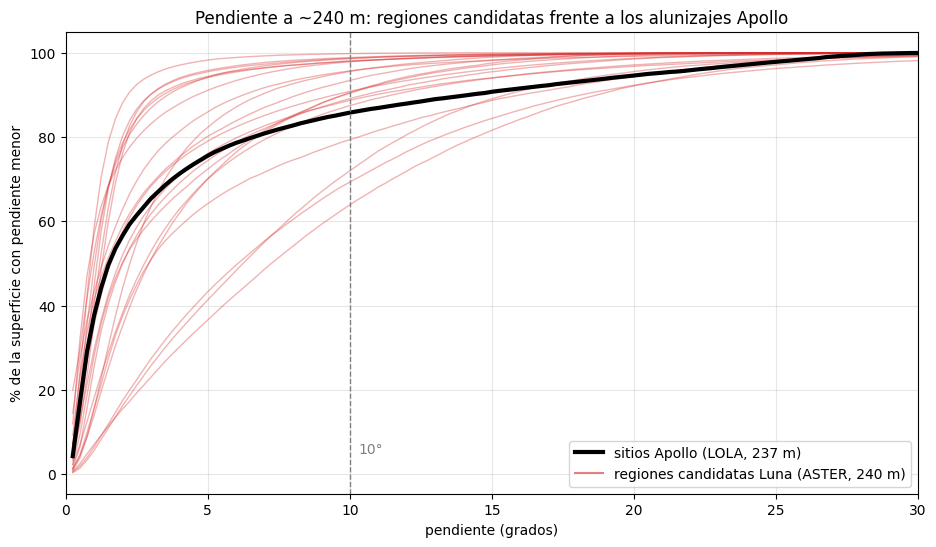

In [7]:
cdf = lambda h: np.cumsum(h) / h.sum() if h.sum() else np.full(len(h), np.nan)
CDF_A = cdf(H_APOLLO)
# Solo para las regiones candidatas de la Luna (para Marte haría falta comparar con los sitios de aterrizaje en Marte, con MOLA)
topo["distancia_apollo"] = [round(float(np.nanmax(np.abs(cdf(HIST240[r.region_id]) - CDF_A))), 3)
                            if r.cuerpo == "luna" and HIST240[r.region_id].sum() else np.nan for r in topo.itertuples()]
# La distancia no dice hacia dónde difiere: una región más llana que los sitios Apollo también "difiere", pero es mejor para una base
LLANO_APOLLO = REF["pct_lt10"]
topo["relieve_vs_apollo"] = np.select(
    [topo.cuerpo != "luna", topo.distancia_apollo.isna(), topo.distancia_apollo <= 0.2, topo.pct_lt10_240m >= LLANO_APOLLO],
    ["no aplica", "sin dato", "parecido a Apollo", "más llano que Apollo"], "más abrupto que Apollo")
topo = topo.drop(columns=["relieve_tipo_apollo"], errors="ignore")
print(f"Sitios Apollo: {LLANO_APOLLO:.1f} % de la superficie con pendiente < 10° (a 237 m)")
topo.to_csv(f"{RES}/topografia_regiones.csv", index=False)
display(topo[topo.cuerpo == "luna"].sort_values("distancia_apollo")[
    ["region_id", "region", "mediana_240m", "pct_lt10_240m", "distancia_apollo", "relieve_vs_apollo", "mediana_30m", "pct_lt10_30m"]])

fig, ax = plt.subplots(figsize=(11, 6))
x = BINS[1:]
for r in topo[topo.cuerpo == "luna"].itertuples():
    if HIST240[r.region_id].sum():
        ax.plot(x, cdf(HIST240[r.region_id]) * 100, color="tab:red", alpha=0.35, lw=1)
ax.plot(x, CDF_A * 100, color="black", lw=3, label="sitios Apollo (LOLA, 237 m)")
ax.plot([], [], color="tab:red", alpha=0.6, label="regiones candidatas Luna (ASTER, 240 m)")
ax.axvline(10, color="grey", ls="--", lw=1); ax.text(10.3, 5, "10°", color="grey")
ax.set_xlim(0, 30); ax.set_xlabel("pendiente (grados)"); ax.set_ylabel("% de la superficie con pendiente menor")
ax.set_title("Pendiente a ~240 m: regiones candidatas frente a los alunizajes Apollo"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

## 7. Capa para la web y registro

In [8]:
def limpio(v):
    if isinstance(v, (float, np.floating)): return None if np.isnan(v) else float(v)
    if isinstance(v, np.integer): return int(v)
    return v

por_region = {r["region_id"]: {k: limpio(v) for k, v in r.items() if k not in ("region_id",)} for r in topo.to_dict("records")}
salida = {"version": VERSION, "unidades": {"pendiente": "grados", "elevacion": "m"},
          "escalas": {"30m": "ASTER GDEM v3 a resolución completa", "240m": "ASTER promediado 8×8, comparable con LOLA LDEM_128"},
          "referencia_apollo": {"por_sitio": apollo.to_dict("records"), "conjunto": {k: round(v, 1) for k, v in REF.items()}},
          "regiones": por_region,
          "nota": "unir con regiones.geojson de cada cuerpo por region_id; teselas_hechas indica si el cálculo está completo"}
json.dump(salida, open(f"{WEB}/topografia.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2, allow_nan=False)
entrada = json.load(open(f"{BASE}/06_web/manifest.json", encoding="utf-8"))
entrada.setdefault("capas", {})["topografia"] = {"version": VERSION, "carpeta": VERSION, "archivo": f"{VERSION}/topografia.json"}
json.dump(entrada, open(f"{BASE}/06_web/manifest.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

registro = {"version": VERSION, "fecha": datetime.datetime.now().isoformat(timespec="seconds"),
            "datos": {"tierra": "NASA ASTER GDEM v3 (ASTGTM v003), doi:10.5067/ASTER/ASTGTM.003",
                      "luna": f"NASA LRO LOLA LDEM_128 (PDS LRO-L-LOLA-4-GDR-V1.0): {ET['url']}",
                      "sitios_apollo": "LROC (2016), Coordinates of Human Features, sistema Mean Earth"},
            "parametros": {"max_teselas_por_region": MAX_TESELAS_POR_REGION, "radio_apollo_km": RADIO_KM, "umbral_parecido_apollo": 0.2},
            "progreso": f"{sum(os.path.exists(f'{CACHE}/{rid}__{t[0]}.npz') for rid, t in trabajo)}/{len(trabajo)} teselas",
            "limitaciones": ["en regiones grandes solo se procesan las teselas con más solape (ver cobertura_teselas)",
                             "ASTER GDEM tiene artefactos en zonas muy planas o con nubes persistentes",
                             "a 30 m el ruido vertical de ASTER infla la pendiente del terreno llano (desiertos planos: 4–7° a 30 m frente a ~1° a 240 m); se compara a 240 m",
                             "la comparación con Apollo es a ~240 m; los riesgos de aterrizaje se miden a escala de metros"]}
json.dump(registro, open(f"{RES}/registro_{VERSION}.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2, default=str)
print("topografia.json:", f"{os.path.getsize(f'{WEB}/topografia.json')/1e3:.0f} KB", "| capas:", list(entrada["capas"]))
print("Espacio en Drive de la caché:", f"{sum(os.path.getsize(p) for p in glob.glob(f'{CACHE}/*'))/1e6:.1f} MB")

topografia.json: 26 KB | capas: ['cuevas', 'topografia']
Espacio en Drive de la caché: 1.6 MB


## 8. Conclusiones
Resultados completos (179 de 179 teselas, 20 regiones Luna y 21 Marte).

**Referencia Apollo (LOLA, 237 m)**: de 0,5° de pendiente mediana (Apollo 12, mar) a 6,2° (Apollo 17, valle entre macizos);
en conjunto, unos 86 % de la superficie con pendiente < 10°.

**Luna (ASTER a 240 m frente a Apollo)**
- *Parecidas a Apollo* (7): Afar (luna-1, -4, -8), Islandia (luna-7), La Meca (luna-15), Turkana (luna-16) y Lahij (luna-17).
- *Más llanas que Apollo* (9): harrats de Medina (luna-3, -13, -19), La Meca (luna-6), Tabuk (luna-9), Siria (luna-2), Marsabit (luna-5),
  Kunene (luna-12) e Islandia (luna-11): entre el 87 % y el 99,8 % con pendiente < 10°.
- *Más abruptas* (4): Tibesti (luna-10, -18), Irán (luna-14) y Tabuk (luna-20), con macizos volcánicos (mediana de 3 a 7°).

**Marte (sin referencia de aterrizaje; solo descripción)**
- Áridas: las más llanas de todo el estudio (mediana 0,8–2,5°, 94–100 % con < 10°).
- Altura: las más abruptas (Pamir 16°, Antofagasta 6°, Sinkiang 4°).
- Polares: intermedias (2,5–5°), salvo Nunavut (marte_polar-4) con 13,5°.

**Limitaciones**
- A 30 m, el ruido vertical de ASTER GDEM (varios metros) infla la pendiente del terreno llano: en desiertos planos sale una mediana de
  4–7° cuando a 240 m es de ~1°. Por eso la comparación se hace a 240 m y los valores a 30 m se toman como cota superior.
- En regiones muy grandes solo se mide una parte (Argelia 1 %, Riad y Sinkiang 12 %, Groenlandia 16 %): ver `cobertura_teselas`.